In [1]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer, util
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
dimension_anchors = {
    "PDI": "This interpretation reflects respect for elders, authority, hierarchy, social order, obedience, and the acceptance of unequal roles based on age, wisdom, or status.",
    
    "IDV": "This interpretation reflects collectivism, community responsibility, family bonds, interdependence, shared identity, cooperation, and prioritising group welfare over individual gain.",
    
    "MAS": "This interpretation reflects achievement, ambition, competition, assertiveness, strength, status, success, and the importance of accomplishment or social recognition.",
    
    "UAI": "This interpretation reflects caution, tradition, rules, predictability, social stability, avoidance of risk, and the preference for certainty over uncertainty.",
    
    "LTO": "This interpretation reflects patience, wisdom, perseverance, long-term thinking, learning from experience, delayed reward, and concern for future consequences.",
    
    "IVR": "This interpretation reflects restraint, self-control, discipline, moderation, control of desires, moral regulation, and limiting indulgence or impulsive pleasure."
}

In [4]:
embedder = SentenceTransformer("all-MiniLM-L6-v2")

In [5]:
anchor_names = list(dimension_anchors.keys())
anchor_texts = list(dimension_anchors.values())

anchor_embeddings = embedder.encode(anchor_texts, convert_to_tensor=True)

In [7]:
df = pd.read_csv("C:\\Users\\temisola\\Final-Year-Project\\datasets\\yoruba_proverb_final_cleaned.csv")
df_long = pd.read_csv("C:\\Users\\temisola\\Final-Year-Project\\datasets\\interpretation_fidelity_rowlevel.csv")

In [8]:
gold_texts = df["interpretation_gold"].astype(str).tolist()
gold_embeddings = embedder.encode(gold_texts, convert_to_tensor=True)

similarity_matrix = util.cos_sim(gold_embeddings, anchor_embeddings).cpu().numpy()

assigned_dimensions = []
assigned_dimension_scores = []

for row in similarity_matrix:
    best_idx = np.argmax(row)
    assigned_dimensions.append(anchor_names[best_idx])
    assigned_dimension_scores.append(row[best_idx])

df["dominant_dimension"] = assigned_dimensions
df["gold_dimension_similarity"] = assigned_dimension_scores

df[["entry_id", "interpretation_gold", "dominant_dimension", "gold_dimension_similarity"]].head()

,entry_id,interpretation_gold,dominant_dimension,gold_dimension_similarity
0,016beb1f83885794,Know your limits.,IVR,0.218226
1,041e7cc871bfebac,One should not destroy oneself simply to get a...,IVR,0.210714
2,04d43584d1d8404a,Do not do things that might constitute temptat...,IVR,0.482970
3,0524e60d4f486d54,"When a venerable person acts like a fool, few ...",PDI,0.325731
4,0584b5795ae7ccb8,A person who wants to be respected must respec...,PDI,0.561361


In [9]:
df["dominant_dimension"].value_counts()

dominant_dimension
UAI    240
PDI    237
LTO    179
IVR    109
IDV    106
MAS     83
Name: count, dtype: int64

In [10]:
interpretation_cols = [
    "deepseek_interpretation",
    "claude_interpretation",
    "gemini_interpretation",
    "mistral_interpretation",
    "llama_interpretation"
]

df_long = df[
    ["entry_id", "interpretation_gold", "dominant_dimension"] + interpretation_cols
].melt(
    id_vars=["entry_id", "interpretation_gold", "dominant_dimension"],
    value_vars=interpretation_cols,
    var_name="model",
    value_name="generated_interpretation"
)

df_long["model"] = df_long["model"].str.replace("_interpretation", "", regex=False)
df_long["generated_interpretation"] = df_long["generated_interpretation"].astype(str).str.strip()
df_long["interpretation_gold"] = df_long["interpretation_gold"].astype(str).str.strip()

df_long = df_long[
    (df_long["generated_interpretation"] != "") &
    (df_long["interpretation_gold"] != "")
].reset_index(drop=True)

df_long.head()

,entry_id,interpretation_gold,dominant_dimension,model,generated_interpretation
0,016beb1f83885794,Know your limits.,IVR,deepseek,This proverb warns against making empty boasts...
1,041e7cc871bfebac,One should not destroy oneself simply to get a...,IVR,deepseek,Do not destroy something useful while expressi...
2,04d43584d1d8404a,Do not do things that might constitute temptat...,IVR,deepseek,This proverb advises discretion and the import...
3,0524e60d4f486d54,"When a venerable person acts like a fool, few ...",PDI,deepseek,Silence in the face of wrongdoing can lead to ...
4,0584b5795ae7ccb8,A person who wants to be respected must respec...,PDI,deepseek,Unused resources or tools are neglected and lo...


In [11]:
gold_emb_long = embedder.encode(df_long["interpretation_gold"].tolist(), convert_to_tensor=True)
model_emb_long = embedder.encode(df_long["generated_interpretation"].tolist(), convert_to_tensor=True)

semantic_scores = util.cos_sim(model_emb_long, gold_emb_long).diagonal().cpu().numpy()

df_long["semantic_fidelity"] = semantic_scores

In [12]:
anchor_lookup = {name: emb for name, emb in zip(anchor_names, anchor_embeddings)}

dimension_embs = []
for dim in df_long["dominant_dimension"]:
    dimension_embs.append(anchor_lookup[dim].cpu().numpy())

dimension_embs = np.stack(dimension_embs)
model_embs_np = model_emb_long.cpu().numpy()

numerator = np.sum(model_embs_np * dimension_embs, axis=1)
denominator = np.linalg.norm(model_embs_np, axis=1) * np.linalg.norm(dimension_embs, axis=1)

df_long["cultural_alignment"] = numerator / denominator

In [21]:
summary_model = (
    df_long.groupby("model")[["semantic_fidelity", "cultural_alignment"]]
    .mean()
    .reset_index()
    .sort_values(by="model", ascending=True)
)

summary_model

,model,semantic_fidelity,cultural_alignment
0,claude,0.317230,0.265928
1,deepseek,0.295761,0.308159
2,gemini,0.341300,0.284528
3,llama,0.263274,0.265887
4,mistral,0.307786,0.290049


In [14]:
summary_dimension = (
    df_long.groupby(["model", "dominant_dimension"])[["semantic_fidelity", "cultural_alignment"]]
    .mean()
    .reset_index()
)

summary_dimension

,model,dominant_dimension,semantic_fidelity,cultural_alignment
0,claude,IDV,0.315373,0.250208
1,claude,IVR,0.310724,0.239810
2,claude,LTO,0.347277,0.280551
3,claude,MAS,0.281424,0.232109
4,claude,PDI,0.336587,0.301639
5,claude,UAI,0.291861,0.250260
6,deepseek,IDV,0.289738,0.251861
7,deepseek,IVR,0.294845,0.274143
8,deepseek,LTO,0.307604,0.349741
9,deepseek,MAS,0.282520,0.271166


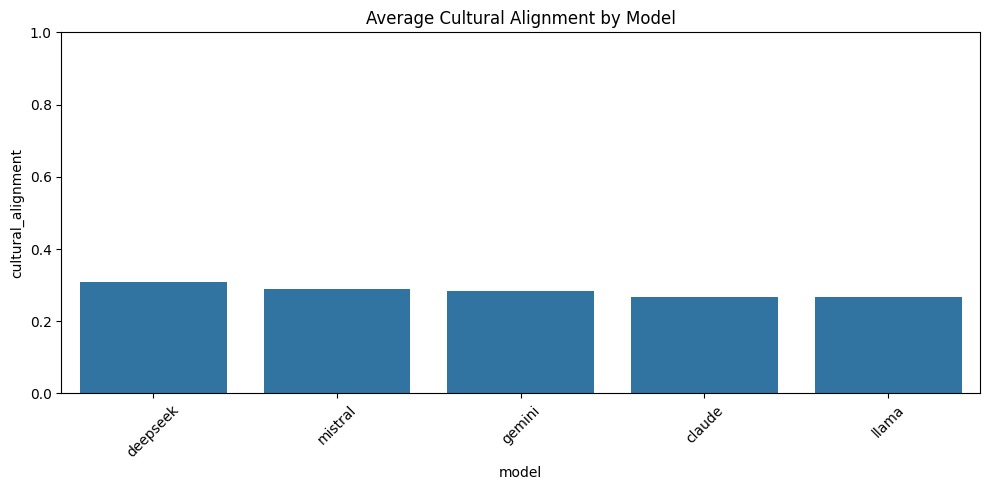

In [16]:
plt.figure(figsize=(10, 5))
sns.barplot(data=summary_model, x="model", y="cultural_alignment")

plt.ylim(0, 1)  # Set y-axis limits to [0, 1] for better visualization

plt.title("Average Cultural Alignment by Model")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

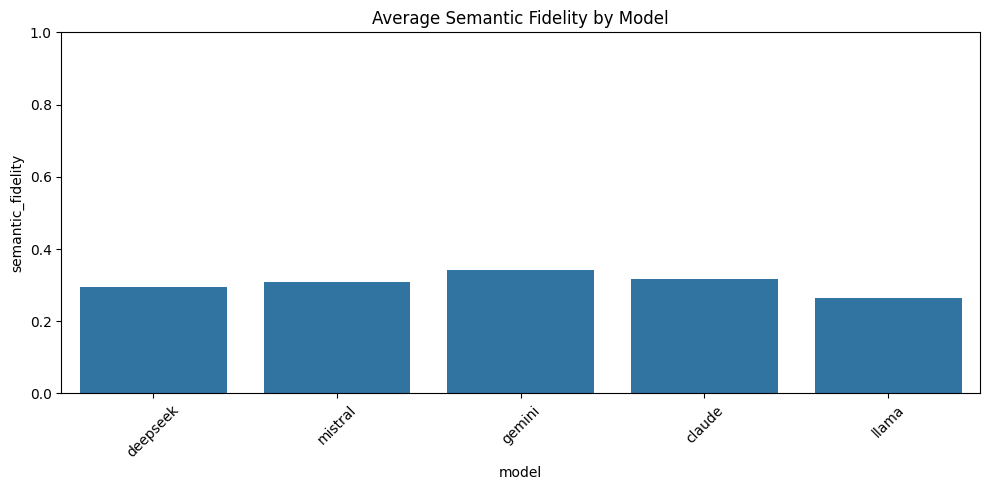

In [17]:
plt.figure(figsize=(10, 5))
sns.barplot(data=summary_model, x="model", y="semantic_fidelity")
plt.ylim(0, 1)
plt.title("Average Semantic Fidelity by Model")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
# Encode all AI interpretations
model_embs_long = embedder.encode(
    df_long["generated_interpretation"].tolist(),
    convert_to_tensor=True
)

# Compute similarity to all 6 anchors
sim_matrix_ai = util.cos_sim(model_embs_long, anchor_embeddings).cpu().numpy()

# Assign best matching dimension
ai_assigned_dims = []
ai_scores = []

for row in sim_matrix_ai:
    idx = np.argmax(row)
    ai_assigned_dims.append(anchor_names[idx])
    ai_scores.append(row[idx])

df_long["ai_dimension"] = ai_assigned_dims
df_long["ai_dimension_score"] = ai_scores

df_long.head()

,entry_id,interpretation_gold,dominant_dimension,model,generated_interpretation,semantic_fidelity,cultural_alignment,ai_dimension,ai_dimension_score
0,016beb1f83885794,Know your limits.,IVR,deepseek,This proverb warns against making empty boasts...,0.201270,0.291708,MAS,0.311728
1,041e7cc871bfebac,One should not destroy oneself simply to get a...,IVR,deepseek,Do not destroy something useful while expressi...,0.470723,0.151333,IVR,0.151333
2,04d43584d1d8404a,Do not do things that might constitute temptat...,IVR,deepseek,This proverb advises discretion and the import...,0.339253,0.323434,UAI,0.464303
3,0524e60d4f486d54,"When a venerable person acts like a fool, few ...",PDI,deepseek,Silence in the face of wrongdoing can lead to ...,0.245188,0.156845,PDI,0.156845
4,0584b5795ae7ccb8,A person who wants to be respected must respec...,PDI,deepseek,Unused resources or tools are neglected and lo...,0.034569,0.038957,IDV,0.128198


In [19]:
comparison = df_long[[
    "entry_id",
    "model",
    "dominant_dimension",
    "ai_dimension",
    "interpretation_gold",
    "generated_interpretation"
]]

comparison.head(10)

,entry_id,model,dominant_dimension,ai_dimension,interpretation_gold,generated_interpretation
0,016beb1f83885794,deepseek,IVR,MAS,Know your limits.,This proverb warns against making empty boasts...
1,041e7cc871bfebac,deepseek,IVR,IVR,One should not destroy oneself simply to get a...,Do not destroy something useful while expressi...
2,04d43584d1d8404a,deepseek,IVR,UAI,Do not do things that might constitute temptat...,This proverb advises discretion and the import...
3,0524e60d4f486d54,deepseek,PDI,PDI,"When a venerable person acts like a fool, few ...",Silence in the face of wrongdoing can lead to ...
4,0584b5795ae7ccb8,deepseek,PDI,IDV,A person who wants to be respected must respec...,Unused resources or tools are neglected and lo...
5,06f4f823fb649363,deepseek,IVR,IVR,Jokes should know limits.,The proverb warns that excessive or improper u...
6,071e49bc6da2cba5,deepseek,PDI,IVR,People should not be slaves to food.,The proverb teaches the importance of moderati...
7,09f2a9471207a66d,deepseek,IVR,IVR,Immoderation brings disgrace.,"The proverb warns against excessive behavior, ..."
8,09fd5face6ec4849,deepseek,MAS,UAI,People should stick to what they are qualified...,Laziness leads to unpreparedness and vulnerabi...
9,0a7d408e260495d2,deepseek,UAI,LTO,Never impose your preferences on other people ...,This proverb emphasizes the limits of human wi...


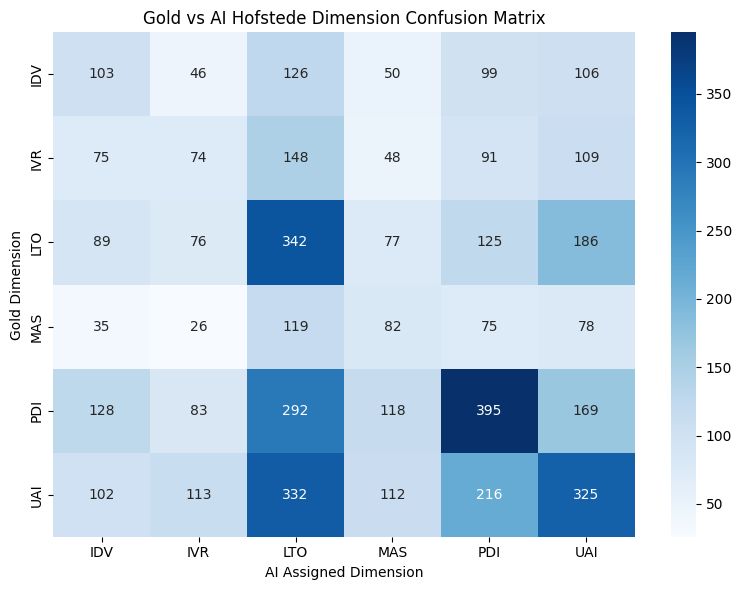

In [22]:
confusion = pd.crosstab(
    df_long["dominant_dimension"],
    df_long["ai_dimension"]
)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues")

plt.title("Gold vs AI Hofstede Dimension Confusion Matrix")
plt.xlabel("AI Assigned Dimension")
plt.ylabel("Gold Dimension")

plt.tight_layout()
plt.show()

In [23]:
mismatches = df_long[df_long["dimension_match"] == 0]

mismatches.sample(5)

,entry_id,interpretation_gold,dominant_dimension,model,generated_interpretation,semantic_fidelity,cultural_alignment,ai_dimension,ai_dimension_score,dimension_match
331,e35e36a15e749fba,"People may withhold their respect from one, bu...",PDI,deepseek,The proverb criticizes laziness and inefficien...,0.161730,0.185038,LTO,0.344953,0
1780,d1c5f1ce758e5991,One should not embark on the endless and futil...,LTO,claude,Some truths are better kept private as sharing...,0.235839,0.139685,UAI,0.259847,0
362,262369f8b430b596,One should associate with one's equals.,PDI,deepseek,People tend to associate with others of simila...,0.427957,0.367715,IDV,0.521992,0
2652,a116cbd610c5abfa,"If one cannot do as one would, one does what o...",IVR,gemini,"When faced with an insurmountable challenge, o...",0.387744,0.184098,LTO,0.367520,0
3815,2eac6223f4543724,Those who refuse instruction lay the foundatio...,PDI,mistral,"Those who heed advice will benefit, while thos...",0.363809,0.212666,UAI,0.329687,0


In [24]:
df.isna().sum()
df_long.isna().sum()

entry_id                    0
interpretation_gold         0
dominant_dimension          0
model                       0
generated_interpretation    0
semantic_fidelity           0
cultural_alignment          0
ai_dimension                0
ai_dimension_score          0
dimension_match             0
dtype: int64

In [25]:
df["dominant_dimension"].value_counts()

dominant_dimension
UAI    240
PDI    237
LTO    179
IVR    109
IDV    106
MAS     83
Name: count, dtype: int64

In [26]:
df.to_csv("final_dataset_with_dimensions.csv", index=False)
df_long.to_csv("final_long_with_scores.csv", index=False)
summary_model.to_csv("summary_model.csv", index=False)
summary_dimension.to_csv("summary_dimension.csv", index=False)